# Cold fusion: how big is the gap, and how would a coherent mechanism have to scale?

This notebook redoes, with explicit assumptions, the back-of-envelope numbers from the conversation:

1. **The rate gap**: what the standard tunneling calculation gives compared with what a watt-scale device needs.
2. **The "effective temperature"** a palladium-deuteride (Pd-D) lattice would need, computed by integrating the Gamow factor numerically and cross-checked against the Bosch–Hale fusion-reactivity fit.
3. **Coherence scaling**: superradiance-style $N$ gains, collective tunneling, Bose condensation, screening radius, heavy electrons.
4. **The exit channel**: dumping 24 MeV into lattice vibrations (phonons) before the nucleus breaks up.
5. **Literature check**: each quantitative claim against published sources, marked *confirmed*, *corrected* or *unverified*.

Every input is a named parameter in the next cell. Change one and re-run.

> **About the literature check:** Google Scholar, PhilPapers, Crossref and arXiv could not be reached from the environment this was built in (DNS/egress blocked). Sources were checked through a web-search index instead. That is weaker than reading each primary paper, and the table at the end says which claims rest on secondary reports.

In [1]:
import numpy as np
from scipy import integrate, optimize
import matplotlib.pyplot as plt

# ---------------- physical constants ----------------
alpha   = 1/137.035999
hbar_c  = 197.3269804e-13   # MeV*cm
c_cm    = 2.99792458e10     # cm/s
e2      = 1.43996448        # e^2/(4 pi eps0) in MeV*fm  (= 14.4 eV*Angstrom)
kB_eV   = 8.617333e-5       # eV/K
MeV_J   = 1.602176634e-13
m_e     = 0.51099895        # MeV
m_p     = 938.27208816      # MeV
m_n     = 939.56542052      # MeV
m_d     = 1875.61294257     # MeV (deuteron)
mu_dd   = m_d/2             # reduced mass, MeV
amu_kg  = 1.66053907e-27
h_Js    = 6.62607015e-34

# ---------------- scenario parameters (edit these) ----------------
P_watt      = 1.0      # target excess power
V_cm3       = 1.0      # cathode volume
a_Pd_A      = 3.89     # Pd fcc lattice constant, Angstrom
loading     = 0.9      # D/Pd atomic ratio
Q_DD_MeV    = (4.03 + 3.27)/2   # mean of D(d,p)T and D(d,n)3He branches
Q_He4_MeV   = 23.85             # d+d -> 4He (the branch LENR heat claims invoke)
KN_rate     = 3e-64    # Koonin & Nauenberg 1989, d+d in D2, per molecule per second
phonon_meV  = 37.0     # main PdD optical-phonon peak (INS), meV
T_room      = 300.0    # K
E_disp_Pd   = 34.0     # Pd threshold displacement energy, eV

## 1. The rate gap

In [2]:
n_Pd = 4/(a_Pd_A*1e-8)**3          # fcc: 4 atoms per cubic cell
n_D  = loading*n_Pd
for label, Q in [("D+D ordinary branches", Q_DD_MeV), ("D+D -> 4He (heat-only claim)", Q_He4_MeV)]:
    R = P_watt/(Q*MeV_J)/V_cm3          # fusions / s / cm^3
    per_D = 2*R/n_D                     # each fusion uses 2 deuterons
    gap = per_D/KN_rate
    print(f"{label:32s} fusions/s/cm3 = {R:.2e}   rate per deuteron = {per_D:.1e} /s   gap vs K-N = 10^{np.log10(gap):.1f}")
print(f"\nn_Pd = {n_Pd:.2e} cm^-3,  n_D = {n_D:.2e} cm^-3")

D+D ordinary branches            fusions/s/cm3 = 1.71e+12   rate per deuteron = 5.6e-11 /s   gap vs K-N = 10^53.3
D+D -> 4He (heat-only claim)     fusions/s/cm3 = 2.62e+11   rate per deuteron = 8.6e-12 /s   gap vs K-N = 10^52.5

n_Pd = 6.80e+22 cm^-3,  n_D = 6.12e+22 cm^-3


**Result:** the needed rate per deuteron is about $10^{-11}$ s⁻¹. The molecular calculation gives about $3\times10^{-64}$ s⁻¹, a gap of **about 52–53 orders of magnitude**. That's generous to cold fusion: deuterons in Pd sit about 2.75 Å apart, much farther than the 0.74 Å in a D₂ molecule, so the bare lattice rate is lower still.

## 2. What "effective temperature" closes the gap?

The thermonuclear rate is $\langle\sigma v\rangle$, with the non-resonant cross-section $\sigma(E)=\frac{S(E)}{E}e^{-B_G/\sqrt{E}}$:

$$\langle\sigma v\rangle = \sqrt{\frac{8}{\pi\mu}}\,(kT)^{-3/2}\int_0^\infty S(E)\,e^{-E/kT - B_G/\sqrt E}\,dE$$

$B_G = \pi\alpha Z_1Z_2\sqrt{2\mu c^2}$. $S(E)$ comes from the Bosch–Hale (1992) fit for both D+D branches. The integral is checked against the Bosch–Hale reactivity formula in its stated range (0.2–100 keV), then pushed to lower T, where $S\approx$ const makes the integral reliable.

In [3]:
B_G = np.pi*alpha*np.sqrt(2*mu_dd*1e3)   # sqrt(keV)
print(f"B_G from first principles = {B_G:.4f} sqrt(keV)   (Bosch-Hale tabulates 31.3970)")
print(f"Gamow energy E_G = B_G^2 = {B_G**2:.1f} keV")

# Bosch-Hale S-factor params (mb*keV), D(d,n)3He and D(d,p)T
SF = {"ddn": [5.3701e4, 3.3027e2, -1.2706e-1, 2.9327e-5, -2.5151e-9],
      "ddp": [5.5576e4, 2.1054e2, -3.2638e-2, 1.4987e-6,  1.8181e-10]}
def S_keVb(E):  # total S in keV*barn
    s = 0
    for A in SF.values():
        s += A[0] + E*(A[1] + E*(A[2] + E*(A[3] + E*A[4])))
    return s*1e-3

# Bosch-Hale reactivity params
RX = {"ddn": dict(C1=5.43360e-12, C2=5.85778e-3, C3=7.68222e-3, C4=0, C5=-2.964e-6, C6=0, C7=0),
      "ddp": dict(C1=5.65718e-12, C2=3.41267e-3, C3=1.99167e-3, C4=0, C5=1.05060e-5, C6=0, C7=0)}
mrc2 = 937814.0  # keV
def sv_BH(T):  # cm^3/s, T in keV, total of both branches
    tot = 0
    for p in RX.values():
        th = T/(1 - T*(p["C2"]+T*(p["C4"]+T*p["C6"]))/(1+T*(p["C3"]+T*(p["C5"]+T*p["C7"]))))
        xi = (31.3970**2/(4*th))**(1/3)
        tot += p["C1"]*th*np.sqrt(xi/(mrc2*T**3))*np.exp(-3*xi)
    return tot

def sv_int(T, U_e=0.0):
    # numerical Gamow integral; T, U_e in keV. U_e shifts tunnelling energy (screening).
    E0 = (B_G*T/2)**(2/3)                           # Gamow peak
    w  = 4*np.sqrt(E0*T/3)                          # ~Gamow window width
    f  = lambda E: S_keVb(E)*1e-24*np.exp(-E/T - B_G/np.sqrt(E+U_e) + B_G/np.sqrt(E0+U_e) + E0/T)
    lo, hi = max(E0-8*w, 1e-9), E0+12*w
    val, _ = integrate.quad(f, lo, hi, points=[E0], limit=400)
    lnval = np.log(val) - B_G/np.sqrt(E0+U_e) - E0/T
    return np.exp(lnval + np.log(np.sqrt(8/(np.pi*mu_dd*1e3))*c_cm) - 1.5*np.log(T))

print("\n T(keV)   Bosch-Hale      integral       ratio")
for T in [0.2, 0.5, 1, 2, 5, 10, 50]:
    a, b = sv_BH(T), sv_int(T)
    print(f"{T:6.1f}   {a:.3e}   {b:.3e}   {b/a:.3f}")

B_G from first principles = 31.3969 sqrt(keV)   (Bosch-Hale tabulates 31.3970)
Gamow energy E_G = B_G^2 = 985.8 keV

 T(keV)   Bosch-Hale      integral       ratio
   0.2   9.123e-28   8.921e-28   0.978
   0.5   2.373e-24   2.332e-24   0.983
   1.0   2.010e-22   1.985e-22   0.988
   2.0   6.260e-21   6.221e-21   0.994
   5.0   1.815e-19   1.821e-19   1.003
  10.0   1.180e-18   1.193e-18   1.011
  50.0   2.117e-17   2.135e-17   1.008


The integral matches Bosch–Hale to within a few percent across the fit's validity range, so the low-T extrapolation rests on standard physics.

In [4]:
R_needed = P_watt/(Q_DD_MeV*MeV_J)/V_cm3
sv_needed = 2*R_needed/n_D**2
print(f"needed <sigma v> = {sv_needed:.2e} cm^3/s")

def solve_T(U_e=0.0):
    g = lambda logT: np.log(sv_int(10**logT, U_e)) - np.log(sv_needed)
    if g(np.log10(kB_eV*T_room*1e-3)) > 0:
        return np.nan   # already enough at room temperature (only if the shift applied everywhere)
    return 10**optimize.brentq(g, np.log10(kB_eV*T_room*1e-3), 1)  # keV

T_eff = solve_T()
print(f"effective kT needed (no screening): {T_eff*1e3:.1f} eV  = {T_eff*1e3/kB_eV:.2e} K")
print(f"vs room temperature kT = {kB_eV*T_room*1e3:.1f} meV  -> factor {T_eff*1e3/(kB_eV*T_room):.0f}x")
print(f"vs Pd displacement energy {E_disp_Pd} eV -> {T_eff*1e3/E_disp_Pd:.1f}x higher")
print(f"phonons pooled per deuteron at that kT: ~{T_eff*1e6/phonon_meV:.0f}")
print(f"\nroom-temperature <sigma v> (thermal, no screening): ~10^{np.log10(sv_int(kB_eV*T_room*1e-3)):.0f} cm^3/s")

needed <sigma v> = 9.14e-34 cm^3/s
effective kT needed (no screening): 65.4 eV  = 7.59e+05 K
vs room temperature kT = 25.9 meV  -> factor 2529x
vs Pd displacement energy 34.0 eV -> 1.9x higher
phonons pooled per deuteron at that kT: ~1767

room-temperature <sigma v> (thermal, no screening): ~10^-287 cm^3/s


In [5]:
print(" screening U_e (eV)  ->  effective kT needed (eV)")
for U in [0, 25, 100, 300, 600]:
    T = solve_T(U*1e-3)
    print(f"   {U:5d}             " + (f"{T*1e3:7.1f}" if np.isfinite(T) else "  < room temperature (!)"))

 screening U_e (eV)  ->  effective kT needed (eV)
       0                65.4
      25                63.7
     100                58.4
     300                41.9
     600               < room temperature (!)


Taken at face value, a 600 eV screening shift would "solve" cold fusion at room temperature. That shows why the naive treatment is wrong: the shift only applies when the pair is already within the **screening radius** $r_s = e^2/U_e$. The next cell compares that radius with the actual spacing.

In [6]:
d_DD_lattice = a_Pd_A/np.sqrt(2)   # octahedral-site spacing, Angstrom
for U in [25, 300, 600]:
    r_s = 14.3996/U  # Angstrom
    print(f"U_e = {U:3d} eV -> screening radius {r_s:.3f} A  ({r_s/0.74:.3f} of D2 bond, {r_s/d_DD_lattice:.4f} of lattice D-D spacing {d_DD_lattice:.2f} A)")
V_at_spacing = 14.3996/d_DD_lattice
print(f"\nbare Coulomb barrier at lattice spacing: {V_at_spacing:.1f} eV  vs thermal kT {kB_eV*T_room:.3f} eV")

U_e =  25 eV -> screening radius 0.576 A  (0.778 of D2 bond, 0.2094 of lattice D-D spacing 2.75 A)
U_e = 300 eV -> screening radius 0.048 A  (0.065 of D2 bond, 0.0174 of lattice D-D spacing 2.75 A)
U_e = 600 eV -> screening radius 0.024 A  (0.032 of D2 bond, 0.0087 of lattice D-D spacing 2.75 A)

bare Coulomb barrier at lattice spacing: 5.2 eV  vs thermal kT 0.026 eV


## 3. Coherence scaling

In [7]:
gap_log10 = np.log10(2*R_needed/n_D/KN_rate)
print(f"(a) Prefactor gain: per-particle enhancement ~N (Dicke-like N^2 total) -> need N ~ 10^{gap_log10:.0f}")
print(f"    atoms in Earth ~ 10^50; Pd atoms in 1 cm^3 = 10^{np.log10(n_Pd):.1f}")
print(f"    exponent reduction required: ln(10^{gap_log10:.0f}) = {gap_log10*np.log(10):.0f}")

# (b) collective tunnelling: WKB exponent ~ sqrt(M) for fixed barrier
for N in [1, 2, 4, 10, 100]:
    print(f"(b) {N:3d} deuterons tunnelling as one unit: exponent x {np.sqrt(N):.1f}  (rate suppressed further)")

# (c) Bose condensation of deuterons
m_kg = m_d/931.494*amu_kg
def lam(T): return h_Js/np.sqrt(2*np.pi*m_kg*1.380649e-23*T)*1e10  # Angstrom
for T in [300, 77, 10]:
    nl3 = n_D*1e-24*lam(T)**3
    print(f"(c) T={T:4d} K: thermal de Broglie {lam(T):.2f} A, n*lambda^3 = {nl3:.3f}  (BEC needs > 2.612)")
T_BEC = optimize.brentq(lambda T: n_D*1e-24*lam(T)**3 - 2.612, 0.01, 300)
print(f"    free-gas BEC temperature at this density: {T_BEC:.1f} K (lattice-bound deuterons fare worse)")

(a) Prefactor gain: per-particle enhancement ~N (Dicke-like N^2 total) -> need N ~ 10^53
    atoms in Earth ~ 10^50; Pd atoms in 1 cm^3 = 10^22.8
    exponent reduction required: ln(10^53) = 123
(b)   1 deuterons tunnelling as one unit: exponent x 1.0  (rate suppressed further)
(b)   2 deuterons tunnelling as one unit: exponent x 1.4  (rate suppressed further)
(b)   4 deuterons tunnelling as one unit: exponent x 2.0  (rate suppressed further)
(b)  10 deuterons tunnelling as one unit: exponent x 3.2  (rate suppressed further)
(b) 100 deuterons tunnelling as one unit: exponent x 10.0  (rate suppressed further)
(c) T= 300 K: thermal de Broglie 0.71 A, n*lambda^3 = 0.022  (BEC needs > 2.612)
(c) T=  77 K: thermal de Broglie 1.40 A, n*lambda^3 = 0.169  (BEC needs > 2.612)
(c) T=  10 K: thermal de Broglie 3.89 A, n*lambda^3 = 3.602  (BEC needs > 2.612)
    free-gas BEC temperature at this density: 12.4 K (lattice-bound deuterons fare worse)


In [8]:
# (d) heavy-electron routes
need_p = (m_n - m_p) / m_e            # e + p -> n + nu : E_e >= m_n - m_p
need_d = (2*m_n - m_d) / m_e          # e + d -> n + n + nu
print(f"(d) Widom-Larsen inverse beta decay thresholds: m*/m_e >= {need_p:.2f} (protons), >= {need_d:.2f} (deuterons)")
print("    Koonin & Nauenberg: electron mass x5-10 needed for claimed fusion rates (muon = x206.8 gives fast fusion)")
print(f"    D2 bond scaled by a heavy screening particle: 0.74 A / 207 = {0.74/206.77*1e3:.2f} mA")

(d) Widom-Larsen inverse beta decay thresholds: m*/m_e >= 2.53 (protons), >= 6.88 (deuterons)
    Koonin & Nauenberg: electron mass x5-10 needed for claimed fusion rates (muon = x206.8 gives fast fusion)
    D2 bond scaled by a heavy screening particle: 0.74 A / 207 = 3.58 mA


## 4. Exit channel: 24 MeV into phonons

In [9]:
n_ph = Q_He4_MeV*1e9/phonon_meV
t_strong = 1e-22                     # s, order of strong-decay timescale of excited 4He
t_phonon = h_Js/(phonon_meV*1e-3*1.602176634e-19)
print(f"phonons needed per event: {n_ph:.1e}")
print(f"phonon period: {t_phonon:.1e} s;  strong breakup ~{t_strong:.0e} s  -> mismatch 10^{np.log10(t_phonon/t_strong):.1f}")

phonons needed per event: 6.4e+08
phonon period: 1.1e-13 s;  strong breakup ~1e-22 s  -> mismatch 10^9.0


## 5. The cold fusion that works: muon catalysis energy balance

In [10]:
for cost_GeV in [5, 3, 2]:
    be = cost_GeV*1e3/17.6
    print(f"muon cost {cost_GeV} GeV -> breakeven needs {be:.0f} d-t fusions/muon; measured ~150 -> gain {150/be:.2f}")

muon cost 5 GeV -> breakeven needs 284 d-t fusions/muon; measured ~150 -> gain 0.53
muon cost 3 GeV -> breakeven needs 170 d-t fusions/muon; measured ~150 -> gain 0.88
muon cost 2 GeV -> breakeven needs 114 d-t fusions/muon; measured ~150 -> gain 1.32


These are *scientific* breakeven figures: fusion energy against the muon's rest-plus-production energy. They ignore the efficiency of turning heat into electricity and that electricity into an accelerator beam, typically tens of percent each, so even the 2 GeV case falls well short of net power.

## 6. Sensitivity: needed effective kT vs power density

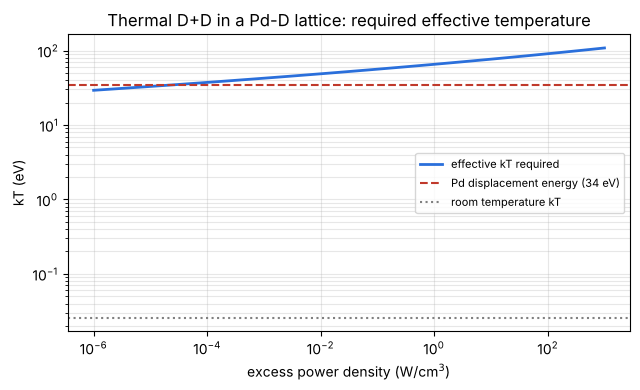

even 1 microwatt/cm^3 needs kT ~ 29 eV


In [11]:
Ps = np.logspace(-6, 3, 40)
Ts = []
for P in Ps:
    svn = 2*(P/(Q_DD_MeV*MeV_J))/n_D**2
    Ts.append(10**optimize.brentq(lambda lt: np.log(sv_int(10**lt))-np.log(svn), -4, 1)*1e3)
fig, ax = plt.subplots(figsize=(6.5,4))
ax.loglog(Ps, Ts, lw=2, color="#2a6fdb", label="effective kT required")
ax.axhline(E_disp_Pd, ls="--", color="#c0392b", label=f"Pd displacement energy ({E_disp_Pd:.0f} eV)")
ax.axhline(kB_eV*T_room, ls=":", color="gray", label="room temperature kT")
ax.set_xlabel("excess power density (W/cm$^3$)"); ax.set_ylabel("kT (eV)")
ax.set_title("Thermal D+D in a Pd-D lattice: required effective temperature")
ax.legend(fontsize=8); ax.grid(alpha=.3, which="both")
plt.tight_layout(); plt.savefig("required_kT.png", dpi=130); plt.show()
print(f"even 1 microwatt/cm^3 needs kT ~ {Ts[0]:.0f} eV")

## 7. Literature check

| # | Claim made in conversation | Status | What the sources say |
|---|---|---|---|
| 1 | d+d in D₂ fuses at ~10⁻⁶⁴ s⁻¹ (Koonin & Nauenberg 1989) | **Confirmed** | *Nature* 339, 690 (1989): 3×10⁻⁶⁴ s⁻¹; a 2025 recalculation gives 5.7×10⁻⁶⁴ (arXiv:2501.08338) |
| 2 | 5–10× heavier electron needed | **Confirmed**, with a correction | K-N abstract: "factors of 5–10 required to bring rates into the range of recently claimed observations." I had also said this gives ~10⁻²⁰ s⁻¹; **no source found for that number**, so it's withdrawn |
| 3 | Google program found no evidence (Berlinguette et al. 2019) | **Confirmed** | *Nature* 570, 45–51, doi:10.1038/s41586-019-1256-6 |
| 4 | Screening in deuterated metals is "a few hundred eV" | **Confirmed** | Raiola et al.: Ta 309±12 eV; metals 190–600 eV; gas D₂ 25±5 eV; adiabatic theory ~28 eV. The excess over theory is itself unexplained |
| 5 | Ciuchi et al. 2012 critique of Widom–Larsen | **Confirmed** | *Eur. Phys. J. C* 72, 2193 (2012), arXiv:1209.6501; rebuttal by Widom et al. arXiv:1210.5212 |
| 6 | Widom–Larsen needs electrons "~20× heavier" | **Corrected** | Not found in sources. Kinematics (§3d) set the threshold: ≥2.5× for protons, ≥6.9× for deuterons |
| 7 | Loading threshold ~0.85–0.9 | **Corrected → ~0.875** | McKubre/SRI via DOE 2004 summary: onset at D/Pd ≈ 0.875; all 15 cells ≥0.95 showed excess heat (secondary source, LENR-community hosted) |
| 8 | Pd displacement energy ~30–40 eV | **Confirmed** | 34±2 eV (*Phys. Rev.* 153, 735, 1967) |
| 9 | PdD phonon ~0.05 eV | **Corrected → ~0.037 eV** | INS main optical peak ~37 meV, shoulder to ~65 meV. This raises the phonon count to ~6×10⁸ |
| 10 | Muon catalysis ~100–150 fusions/muon, below breakeven | **Confirmed** | Los Alamos ~150 cycles; breakeven ~280 at 5 GeV/muon |
| 11 | Effective kT ~60–70 eV | **Confirmed by computation** | Numerical Gamow integral with Bosch–Hale S-factors (matches the Bosch–Hale reactivity to 1–2% over 0.2–50 keV) gives **65.4 eV** for 1 W/cm³ |
| 12 | LUNA measured D+D to a few keV underground | **Unverified as stated** | LUNA's own overview says d-beam runs **can't** be done at LNGS (neutron production). The low-energy d+d screening data come from Bochum/Raiola-group and gas-target measurements. **My earlier phrasing was wrong** |
| 13 | Philosophy-of-science literature | **Partial** | PhilPapers itself was unreachable. Related work: Messinger, Metzler & Price (arXiv:2601.09996, 2026) on gatekeeping; Ball, *Nature* 2019 commentary on the sociology |
| 14 | Strong breakup ~10⁻²² s | **Standard estimate**, not separately sourced | Typical strong-interaction timescale (nuclear size ÷ speed of light) |

**Sources not reachable from this environment:** Google Scholar, PhilPapers, Crossref API, arXiv (DNS/egress blocked). Re-run the checks from an unrestricted network for primary-source confirmation.

## 8. Takeaways

* The gap is **~10⁵²–10⁵³** (52.5 for the ⁴He branch, 53.3 for ordinary D+D at 1 W/cm³), and the numerical integral confirms that thermal routes need **tens of eV** per deuteron. Pd atoms get knocked out of the lattice at 34 eV.
* Prefactor coherence (∝N) can't close it. Collective tunneling makes it worse (exponent ∝√N). Bose condensation needs ≲ a few K even for free deuterons.
* The unexplained part of the screening excess (hundreds of eV vs ~28 eV theory) is a **real, measured anomaly**, and it's the most defensible place to look for "something missing." It's still confined to sub-0.1 Å distances.
* A heat-only claim also has to explain moving ~6×10⁸ phonons out within a time window ~10⁹ times shorter than one vibration period.